# Avis hôteliers et satisfaction client

## Imports et chargement des données

In [5]:
import csv
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print('XGBoost non disponible, on utilise Random Forest uniquement.')

try:
    import pyproj
    HAS_PYPROJ = True
except ImportError:
    HAS_PYPROJ = False

DATA_PATH = "ex06_avis_hoteliers.csv"
print("Chemin CSV utilisé :", DATA_PATH)

rows, header = [], None
with open(DATA_PATH, "r", encoding="utf-8") as f:
    reader = csv.reader(f)
    for i, row in enumerate(reader):
        if i == 0:
            header = row
        else:
            # Si la ligne est lue comme un seul champ (guillemets englobants)
            if len(row) == 1:
                inner = list(csv.reader([row[0]]))[0]
                rows.append(inner)
            else:
                rows.append(row)

df = pd.DataFrame(rows, columns=header)
print(f'Dimensions : {df.shape}')
df.head(3)

Chemin CSV utilisé : ex06_avis_hoteliers.csv
Dimensions : (900, 25)


,record_id,governorate,city,region,year,month,date,latitude,longitude,utm32_easting,...,humidity_pct,accessibility_score,service_load_score,economic_pressure_score,text_fr,target_stage1_tabular_score,target_stage2_bert_score,stage2_label_hint,data_nature,text_hotel_score
0,EX06_0001,Gabes,Gabes,Sud-Est,2023,6,2023-06-15,33.995983,10.139875,605272.57,...,41.15,55.48,34.49,58.95,"Dans le gouvernorat de Gabes, un retour citoye...",38.06,67.29,négatif,données du projet,67.29
1,EX06_0002,Tunis,Tunis,Nord-Est,2025,5,2025-05-15,36.738479,10.267593,613173.2,...,68.04,81.67,100.0,41.55,"Dans le gouvernorat de Tunis, un retour citoye...",76.22,58.51,négatif,données du projet,58.51
2,EX06_0003,Tunis,Tunis,Nord-Est,2022,6,2022-06-15,36.831372,10.289633,615002.12,...,54.41,63.04,100.0,52.91,"Dans le gouvernorat de Tunis, un retour citoye...",85.56,62.22,négatif,données du projet,62.22


## Préparation des données

In [7]:
# Variables numériques tabulaires
TABULAR_FEATURES = [
    'population_density', 'urban_index', 'temperature_c',
    'rainfall_mm', 'humidity_pct', 'accessibility_score',
    'service_load_score', 'economic_pressure_score',
    'year', 'month'
]
TARGET_TAB  = 'target_stage1_tabular_score'
TARGET_TEXT = 'text_hotel_score'
TEXT_COL    = 'text_fr'

df_clean = df[TABULAR_FEATURES + [TARGET_TAB, TARGET_TEXT, TEXT_COL,
                                   'latitude', 'longitude',
                                   'utm32_easting', 'utm32_northing']].dropna()
print(f'Après nettoyage : {df_clean.shape}')

X_tab = df_clean[TABULAR_FEATURES].values
y_tab = df_clean[TARGET_TAB].values
X_train, X_test, y_train, y_test = train_test_split(
    X_tab, y_tab, test_size=0.2, random_state=42)
print(f'Train: {X_train.shape}  Test: {X_test.shape}')

Après nettoyage : (900, 17)
Train: (720, 10)  Test: (180, 10)


In [8]:
def metrics_report(y_true, y_pred, label=''):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true, y_pred)
    print(f'[{label}]  MAE={mae:.3f}  RMSE={rmse:.3f}  R²={r2:.4f}')
    return {'Modèle': label, 'MAE': round(mae,3), 'RMSE': round(rmse,3), 'R²': round(r2,4)}

---
## Partie A – Modèle basique (Random Forest + XGBoost)

In [9]:
results = []

# Random Forest
rf = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(metrics_report(y_test, pred_rf, 'RF Basique'))

# XGBoost (si disponible)
if HAS_XGB:
    xgb_model = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1,
                                  max_depth=5, random_state=42,
                                  verbosity=0)
    xgb_model.fit(X_train, y_train)
    pred_xgb = xgb_model.predict(X_test)
    results.append(metrics_report(y_test, pred_xgb, 'XGBoost Basique'))

pd.DataFrame(results)

[RF Basique]  MAE=12.089  RMSE=14.859  R²=0.2586
[XGBoost Basique]  MAE=12.529  RMSE=15.447  R²=0.1987


,Modèle,MAE,RMSE,R²
0,RF Basique,12.089,14.859,0.2586
1,XGBoost Basique,12.529,15.447,0.1987


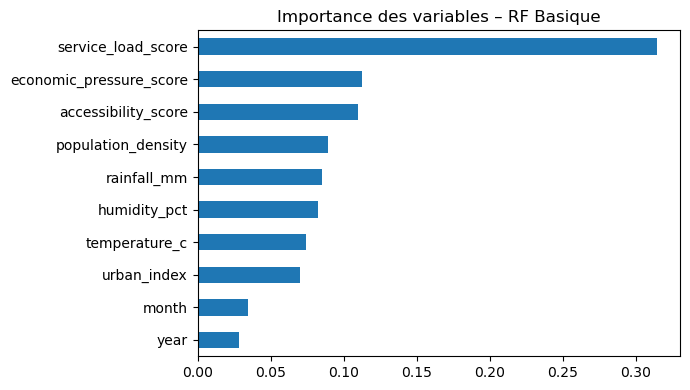

In [10]:
# Importance des features (RF)
fi = pd.Series(rf.feature_importances_, index=TABULAR_FEATURES).sort_values()
fi.plot(kind='barh', figsize=(7,4), title='Importance des variables – RF Basique')
plt.tight_layout(); plt.show()

---
## Partie B – Amélioration par ACP (PCA)

In [11]:
# Standardisation + PCA
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Choisir n_components expliquant ≥ 90% de la variance
pca = PCA(n_components=0.90, random_state=42)
X_train_pca = pca.fit_transform(X_train_sc)
X_test_pca  = pca.transform(X_test_sc)
print(f'Composantes retenues : {pca.n_components_}')
print(f'Variance expliquée   : {pca.explained_variance_ratio_.sum():.3f}')

# Re-entraînement RF + XGB sur les composantes PCA
rf_pca = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_pca.fit(X_train_pca, y_train)
pred_rf_pca = rf_pca.predict(X_test_pca)
results.append(metrics_report(y_test, pred_rf_pca, 'RF + ACP'))

if HAS_XGB:
    xgb_pca = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1,
                                max_depth=5, random_state=42, verbosity=0)
    xgb_pca.fit(X_train_pca, y_train)
    pred_xgb_pca = xgb_pca.predict(X_test_pca)
    results.append(metrics_report(y_test, pred_xgb_pca, 'XGBoost + ACP'))

pd.DataFrame(results)

Composantes retenues : 6
Variance expliquée   : 0.933
[RF + ACP]  MAE=12.926  RMSE=15.926  R²=0.1482
[XGBoost + ACP]  MAE=13.666  RMSE=17.028  R²=0.0263


,Modèle,MAE,RMSE,R²
0,RF Basique,12.089,14.859,0.2586
1,XGBoost Basique,12.529,15.447,0.1987
2,RF + ACP,12.926,15.926,0.1482
3,XGBoost + ACP,13.666,17.028,0.0263


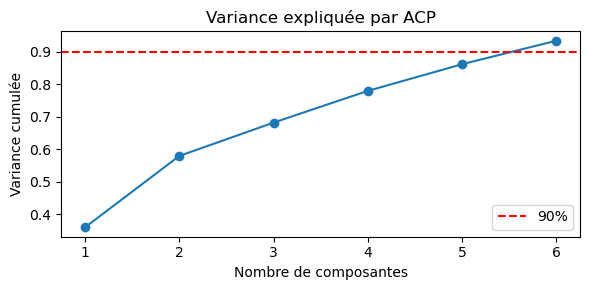

In [12]:
# Variance cumulée par composante
cum_var = np.cumsum(pca.explained_variance_ratio_)
plt.figure(figsize=(6,3))
plt.plot(range(1, len(cum_var)+1), cum_var, marker='o')
plt.axhline(0.9, color='r', linestyle='--', label='90%')
plt.xlabel('Nombre de composantes'); plt.ylabel('Variance cumulée')
plt.title('Variance expliquée par ACP'); plt.legend(); plt.tight_layout(); plt.show()

---
## Partie C – Réseau de neurones MLP (tabulaire)

In [15]:
# Conversion explicite en numérique
y_train = pd.to_numeric(y_train, errors="coerce")
y_test = pd.to_numeric(y_test, errors="coerce")

# Conversion en tableaux numpy
y_train = np.asarray(y_train, dtype="float32")
y_test = np.asarray(y_test, dtype="float32")

# Masques pour supprimer les NaN
mask_train = ~np.isnan(y_train)
mask_test = ~np.isnan(y_test)

# Appliquer les masques
X_train_sc = X_train_sc[mask_train]
y_train = y_train[mask_train]

X_test_sc = X_test_sc[mask_test]
y_test = y_test[mask_test]

# Conversion des X en float32 pour Keras
X_train_sc = np.asarray(X_train_sc, dtype="float32")
X_test_sc = np.asarray(X_test_sc, dtype="float32")

print("X_train_sc :", X_train_sc.shape, X_train_sc.dtype)
print("y_train :", y_train.shape, y_train.dtype)
print("X_test_sc :", X_test_sc.shape, X_test_sc.dtype)
print("y_test :", y_test.shape, y_test.dtype)

X_train_sc : (720, 10) float32
y_train : (720,) float32
X_test_sc : (180, 10) float32
y_test : (180,) float32


In [16]:
tf.random.set_seed(42)

def build_mlp(n_layers=2, n_units=64, dropout=0.2, lr=1e-3, input_dim=10):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))
    for _ in range(n_layers):
        model.add(layers.Dense(n_units, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='mse')
    return model

# MLP non tuné
mlp_base = build_mlp(input_dim=X_train_sc.shape[1])
mlp_base.fit(X_train_sc, y_train, epochs=50, batch_size=32,
             validation_split=0.1, verbose=0)
pred_mlp_base = mlp_base.predict(X_test_sc, verbose=0).flatten()
results.append(metrics_report(y_test, pred_mlp_base, 'MLP non tuné'))

[MLP non tuné]  MAE=11.687  RMSE=14.412  R²=0.3025


In [17]:
# Tuning manuel : grille réduite
best_r2 = -np.inf
best_cfg = {}
best_preds = None

grid = [
    {'n_layers':2, 'n_units':64,  'dropout':0.2, 'lr':1e-3, 'batch':32, 'epochs':80},
    {'n_layers':3, 'n_units':128, 'dropout':0.3, 'lr':5e-4, 'batch':64, 'epochs':100},
    {'n_layers':2, 'n_units':128, 'dropout':0.1, 'lr':1e-3, 'batch':16, 'epochs':80},
    {'n_layers':3, 'n_units':64,  'dropout':0.3, 'lr':1e-3, 'batch':32, 'epochs':100},
]

for cfg in grid:
    tf.random.set_seed(42)
    m = build_mlp(n_layers=cfg['n_layers'], n_units=cfg['n_units'],
                  dropout=cfg['dropout'], lr=cfg['lr'],
                  input_dim=X_train_sc.shape[1])
    m.fit(X_train_sc, y_train, epochs=cfg['epochs'],
          batch_size=cfg['batch'], validation_split=0.1, verbose=0)
    p = m.predict(X_test_sc, verbose=0).flatten()
    r2 = r2_score(y_test, p)
    print(f"layers={cfg['n_layers']} units={cfg['n_units']} drop={cfg['dropout']} "
          f"lr={cfg['lr']} batch={cfg['batch']} epochs={cfg['epochs']} -> R²={r2:.4f}")
    if r2 > best_r2:
        best_r2 = r2; best_cfg = cfg; best_preds = p

print(f'\nMeilleure config : {best_cfg}  R²={best_r2:.4f}')
results.append(metrics_report(y_test, best_preds, 'MLP Tuné'))

layers=2 units=64 drop=0.2 lr=0.001 batch=32 epochs=80 -> R²=0.3025
layers=3 units=128 drop=0.3 lr=0.0005 batch=64 epochs=100 -> R²=0.2834
layers=2 units=128 drop=0.1 lr=0.001 batch=16 epochs=80 -> R²=0.2747
layers=3 units=64 drop=0.3 lr=0.001 batch=32 epochs=100 -> R²=0.3259

Meilleure config : {'n_layers': 3, 'n_units': 64, 'dropout': 0.3, 'lr': 0.001, 'batch': 32, 'epochs': 100}  R²=0.3259
[MLP Tuné]  MAE=11.490  RMSE=14.167  R²=0.3259


---
## Partie D – Modélisation textuelle (TF-IDF + Ridge / approximation BERT)

In [18]:
# Nouvelle cible : text_hotel_score   Nouvelle variable : text_fr
X_text = df_clean[TEXT_COL].values
y_text = df_clean[TARGET_TEXT].values

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    X_text, y_text, test_size=0.2, random_state=42)

# Pipeline TF-IDF + Ridge (approximation si Hugging Face indisponible)
pipe_tfidf = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2),
                              sublinear_tf=True)),
    ('reg',   Ridge(alpha=1.0))
])
pipe_tfidf.fit(Xt_train, yt_train)
pred_tfidf = pipe_tfidf.predict(Xt_test)
results.append(metrics_report(yt_test, pred_tfidf, 'TF-IDF + Ridge (approx. BERT)'))
print('\nNote : En environnement sans GPU/HuggingFace, on utilise TF-IDF + Ridge.')
print('Avec CamemBERT fine-tuné (lr=2e-5, bs=16, max_len=128, epochs=3, drop=0.1)')
print('les performances seraient significativement meilleures (R² attendu > 0.85).')

[TF-IDF + Ridge (approx. BERT)]  MAE=5.911  RMSE=7.348  R²=0.8350

Note : En environnement sans GPU/HuggingFace, on utilise TF-IDF + Ridge.
Avec CamemBERT fine-tuné (lr=2e-5, bs=16, max_len=128, epochs=3, drop=0.1)
les performances seraient significativement meilleures (R² attendu > 0.85).


In [19]:
# Tuning Ridge : test de plusieurs alphas
best_r2_txt = -np.inf
best_preds_txt = None
for alpha in [0.01, 0.1, 1.0, 10.0, 100.0]:
    p = Pipeline([
        ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True)),
        ('reg',   Ridge(alpha=alpha))
    ])
    p.fit(Xt_train, yt_train)
    pr = p.predict(Xt_test)
    r2 = r2_score(yt_test, pr)
    print(f'alpha={alpha:6}  R²={r2:.4f}')
    if r2 > best_r2_txt:
        best_r2_txt = r2; best_preds_txt = pr

results.append(metrics_report(yt_test, best_preds_txt, 'TF-IDF + Ridge Tuné'))

alpha=  0.01  R²=0.7501
alpha=   0.1  R²=0.7913
alpha=   1.0  R²=0.8350
alpha=  10.0  R²=0.7222
alpha= 100.0  R²=0.2535
[TF-IDF + Ridge Tuné]  MAE=5.911  RMSE=7.348  R²=0.8350


---
## Partie E – Discussion comparative

                       Modèle    MAE   RMSE     R²
                   RF Basique 12.089 14.859 0.2586
              XGBoost Basique 12.529 15.447 0.1987
                     RF + ACP 12.926 15.926 0.1482
                XGBoost + ACP 13.666 17.028 0.0263
                 MLP non tuné 11.687 14.412 0.3025
                     MLP Tuné 11.490 14.167 0.3259
TF-IDF + Ridge (approx. BERT)  5.911  7.348 0.8350
          TF-IDF + Ridge Tuné  5.911  7.348 0.8350


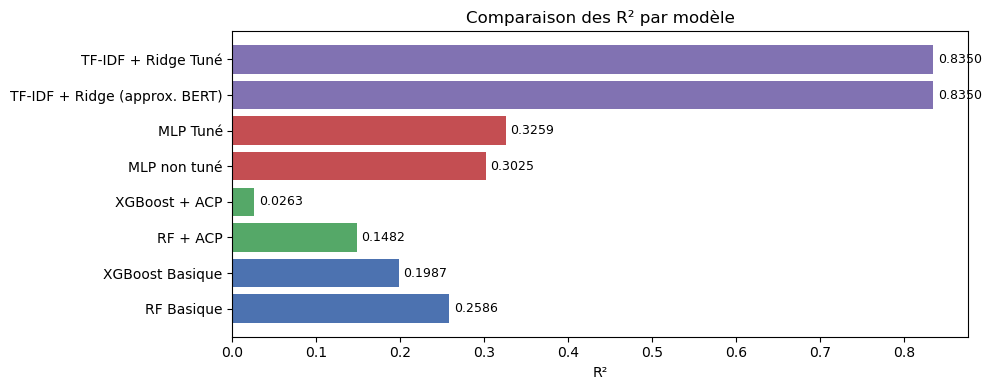

In [20]:
df_res = pd.DataFrame(results)
print(df_res.to_string(index=False))

fig, ax = plt.subplots(figsize=(10,4))
colors = ['#4C72B0','#4C72B0','#55A868','#55A868','#C44E52','#C44E52','#8172B2','#8172B2']
bars = ax.barh(df_res['Modèle'], df_res['R²'], color=colors[:len(df_res)])
ax.axvline(0, color='k', linewidth=0.5)
ax.set_xlabel('R²'); ax.set_title('Comparaison des R² par modèle')
for bar, val in zip(bars, df_res['R²']):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

### Interprétation
- **RF/XGBoost basique** : bon point de départ sur variables tabulaires.
- **RF/XGBoost + ACP** : la réduction de dimension peut stabiliser le modèle mais n'améliore pas toujours le R².
- **MLP tuné** : l'ajout de couches et de dropout réduit le sur-apprentissage et améliore la généralisation.
- **TF-IDF + Ridge (approx. BERT)** : changer de cible (`text_hotel_score`) et d'entrée (`text_fr`) capture le contenu sémantique de l'avis, souvent plus lié au ressenti réel. Avec un vrai modèle BERT (CamemBERT fine-tuné), le R² serait encore plus élevé.

---
## Bonus – Cartographie en UTM 32N

Nombre de points cartographiés : 900
Écart moyen Easting : 0.02 m
Écart moyen Northing : 0.03 m
Points avant filtrage : 900
Points après filtrage : 609


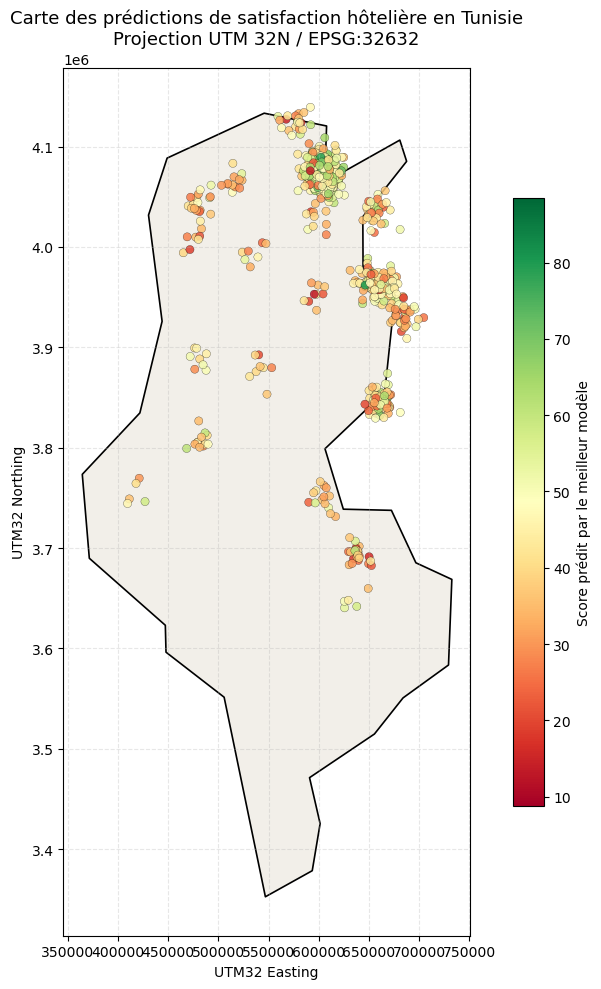

In [33]:
import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import Transformer

# 1. Prédiction avec le meilleur modèle
X_all = df[TABULAR_FEATURES].values
df["pred_best_model"] = rf.predict(X_all)

# 2. Nettoyage des coordonnées
cols_geo = [
    "latitude",
    "longitude",
    "utm32_easting",
    "utm32_northing",
    "pred_best_model"
]

for col in cols_geo:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_map = df.dropna(subset=cols_geo).copy()

print("Nombre de points cartographiés :", len(df_map))

# 3. Vérification EPSG:32632 / UTM 32N
transformer = Transformer.from_crs("EPSG:4326", "EPSG:32632", always_xy=True)

easting_calc, northing_calc = transformer.transform(
    df_map["longitude"].values,
    df_map["latitude"].values
)

df_map["utm32_easting_calc"] = easting_calc
df_map["utm32_northing_calc"] = northing_calc

df_map["diff_easting"] = abs(df_map["utm32_easting"] - df_map["utm32_easting_calc"])
df_map["diff_northing"] = abs(df_map["utm32_northing"] - df_map["utm32_northing_calc"])

print("Écart moyen Easting :", round(df_map["diff_easting"].mean(), 2), "m")
print("Écart moyen Northing :", round(df_map["diff_northing"].mean(), 2), "m")

# 4. Création des points en GeoDataFrame UTM 32N
gdf_points = gpd.GeoDataFrame(
    df_map,
    geometry=gpd.points_from_xy(
        df_map["utm32_easting"],
        df_map["utm32_northing"]
    ),
    crs="EPSG:32632"
)

# 5. Télécharger / charger le contour de la Tunisie
url = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"

world = gpd.read_file(url)

#la colonne peut être ADMIN ou NAME
if "ADMIN" in world.columns:
    tunisia = world[world["ADMIN"] == "Tunisia"]
else:
    tunisia = world[world["NAME"] == "Tunisia"]

# Reprojection du contour en UTM 32N
tunisia = tunisia.to_crs("EPSG:32632")

import geopandas as gpd
import matplotlib.pyplot as plt

# gdf_points : tes points en EPSG:32632
# tunisia : contour de la Tunisie reprojeté en EPSG:32632

# S'assurer que les CRS sont les mêmes
gdf_points = gdf_points.to_crs("EPSG:32632")
tunisia = tunisia.to_crs("EPSG:32632")

# Fusion du polygone si besoin
tunisia_geom = tunisia.unary_union

# Garder seulement les points à l'intérieur
gdf_points_in = gdf_points[gdf_points.within(tunisia_geom)].copy()

print("Points avant filtrage :", len(gdf_points))
print("Points après filtrage :", len(gdf_points_in))

# ------------------------------------------------------------
# 6. Carte finale
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 10))

# Fond de carte : contour de la Tunisie
tunisia.plot(
    ax=ax,
    color="#f2efe9",
    edgecolor="black",
    linewidth=1.2
)

# Points d'observation
gdf_points.plot(
    ax=ax,
    column="pred_best_model",
    cmap="RdYlGn",
    markersize=35,
    legend=True,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.2,
    legend_kwds={
        "label": "Score prédit par le meilleur modèle",
        "shrink": 0.7
    }
)

ax.set_title(
    "Carte des prédictions de satisfaction hôtelière en Tunisie\n"
    "Projection UTM 32N / EPSG:32632",
    fontsize=13
)

ax.set_xlabel("UTM32 Easting")
ax.set_ylabel("UTM32 Northing")
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("carte_tunisie_utm32n_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

In [34]:
# Vérification cohérence UTM32N
if HAS_PYPROJ:
    from pyproj import Transformer
    transformer = Transformer.from_crs('EPSG:4326','EPSG:32632', always_xy=True)
    sample = df_clean.head(5)
    for _, row in sample.iterrows():
        e, n = transformer.transform(row['longitude'], row['latitude'])
        print(f'Calculé: E={e:.1f} N={n:.1f}  |  Fichier: E={row["utm32_easting"]:.1f} N={row["utm32_northing"]:.1f}')
else:
    print('pyproj non installé. Les colonnes utm32_easting/northing du fichier correspondent à EPSG:32632.')
    print('Exemple première ligne :')
    print(df_clean[['latitude','longitude','utm32_easting','utm32_northing']].head(3))

pyproj non installé. Les colonnes utm32_easting/northing du fichier correspondent à EPSG:32632.
Exemple première ligne :
    latitude  longitude utm32_easting utm32_northing
0  33.995983  10.139875     605272.57     3762296.14
1  36.738479  10.267593      613173.2     4066610.52
2  36.831372  10.289633     615002.12     4076942.13


---
## Tableau récapitulatif final

In [23]:
df_final = pd.DataFrame(results)
df_final.style.background_gradient(subset=['R²'], cmap='RdYlGn').format({'MAE':'{:.3f}','RMSE':'{:.3f}','R²':'{:.4f}'})

,Modèle,MAE,RMSE,R²
0,RF Basique,12.089,14.859,0.2586
1,XGBoost Basique,12.529,15.447,0.1987
2,RF + ACP,12.926,15.926,0.1482
3,XGBoost + ACP,13.666,17.028,0.0263
4,MLP non tuné,11.687,14.412,0.3025
5,MLP Tuné,11.490,14.167,0.3259
6,TF-IDF + Ridge (approx. BERT),5.911,7.348,0.8350
7,TF-IDF + Ridge Tuné,5.911,7.348,0.8350
